# Customer Churn Prediction

## Overview
Customer churn is a major challenge for businesses, particularly in the telecommunications industry, where retaining existing customers is essential for sustainable growth.

This project focuses on developing a machine learning classification model to predict whether a telecom customer is likely to leave the company based on their demographic information, account details, subscribed services, and billing information.

Using the IBM Telco Customer Churn dataset, I performed exploratory data analysis, data cleaning, preprocessing, and model training to identify patterns associated with customer churn and evaluate the performance of different classification algorithms.

The goal is to understand the factors associated with customer churn and build a predictive model that can help businesses identify customers who may be at risk of leaving.

## Import Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score

sns.set(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (8, 5)

import warnings
warnings.filterwarnings('ignore')

import joblib

## Initial Data Exploration

In [4]:
df = pd.read_csv('Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape

(7043, 21)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [15]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [32]:
df['Churn'].replace({'Yes': 1, 'No': 0}).groupby(df['Contract']).mean() * 100

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: object

## Exploratory Data Analysis

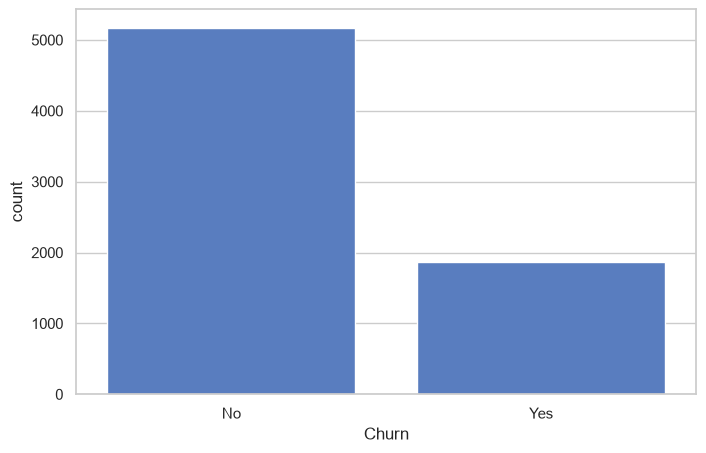

In [51]:
sns.countplot(x='Churn', data=df)
plt.show()

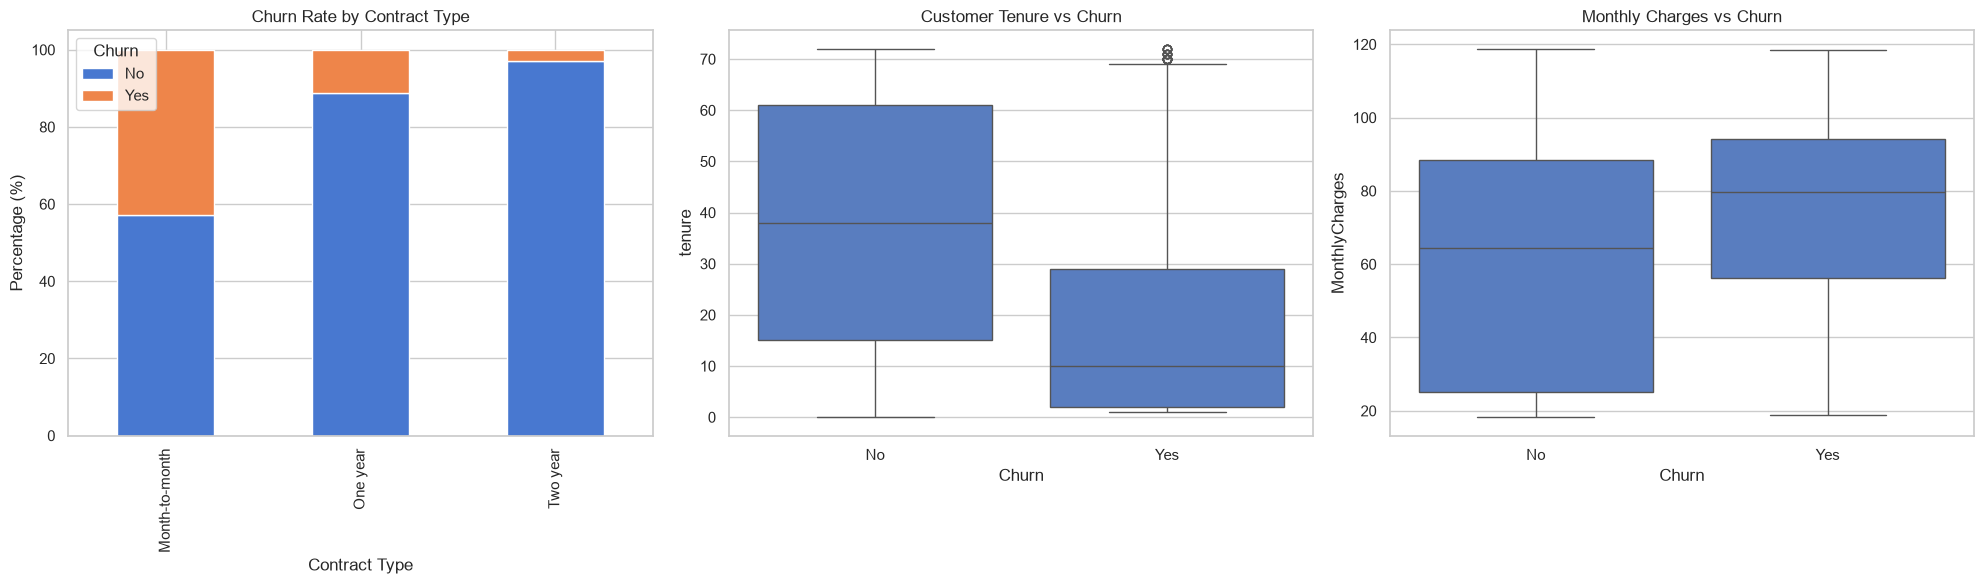

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Contract vs Churn
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
contract_churn.plot(kind='bar', stacked=True, ax=axes[0])

axes[0].set_title('Churn Rate by Contract Type')
axes[0].set_ylabel('Percentage (%)')
axes[0].set_xlabel('Contract Type')
axes[0].legend(title='Churn')

# Tenure vs Churn
sns.boxplot(x='Churn', y='tenure', data=df, ax=axes[1])
axes[1].set_title('Customer Tenure vs Churn')

# Monthly Charges vs Churn
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[2])
axes[2].set_title('Monthly Charges vs Churn')

plt.tight_layout()
plt.show()

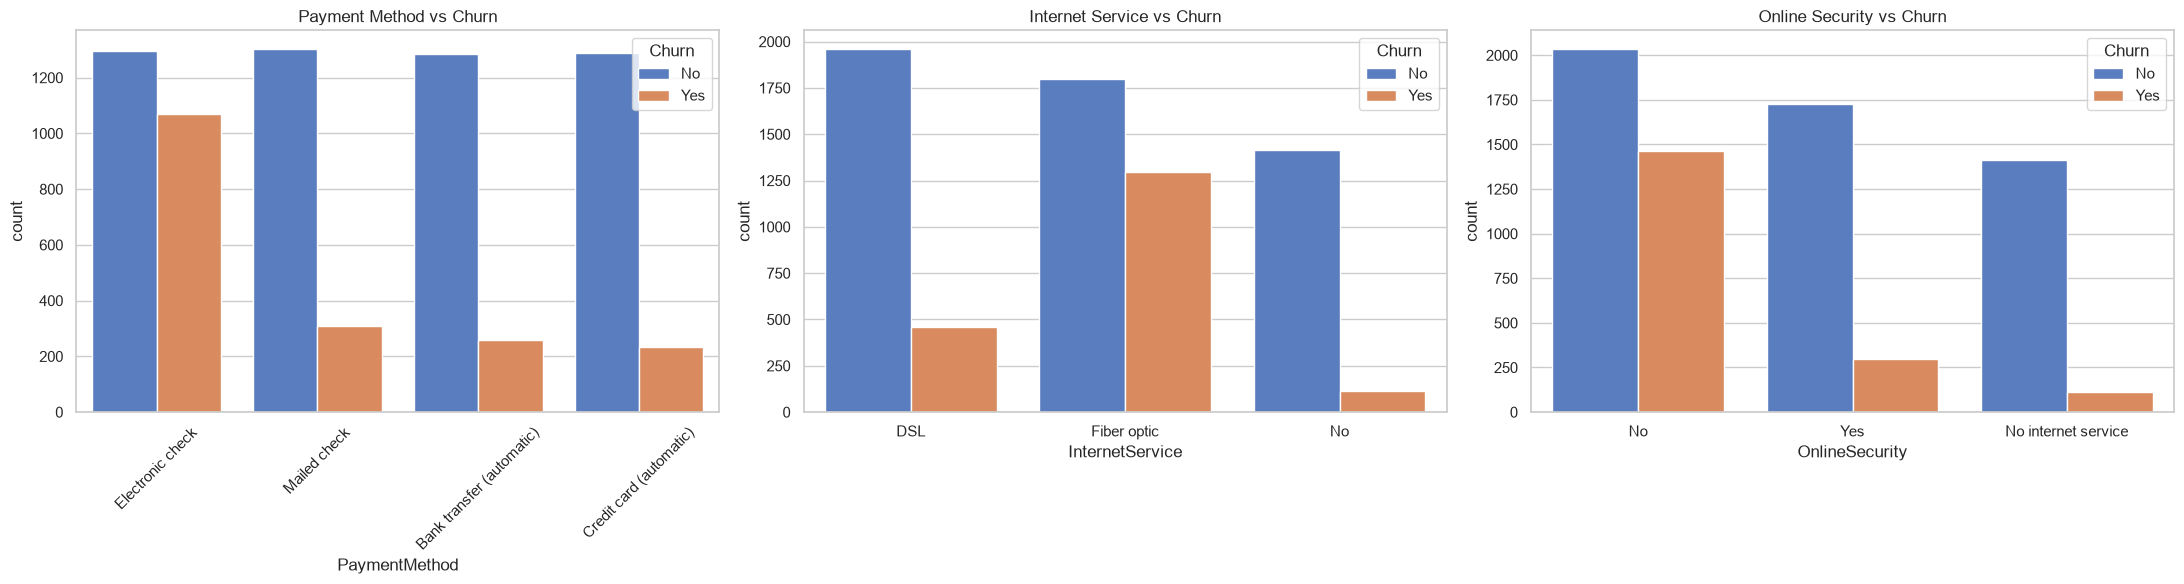

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# Payment Method vs Churn
sns.countplot(x='PaymentMethod', hue='Churn', data=df, ax=axes[0])
axes[0].set_title('Payment Method vs Churn')
axes[0].tick_params(axis='x', rotation=45)

# Internet Service vs Churn
sns.countplot(x='InternetService', hue='Churn', data=df, ax=axes[1])
axes[1].set_title('Internet Service vs Churn')

# Online Security vs Churn
sns.countplot(x='OnlineSecurity', hue='Churn', data=df, ax=axes[2])
axes[2].set_title('Online Security vs Churn')

plt.tight_layout()
plt.show()

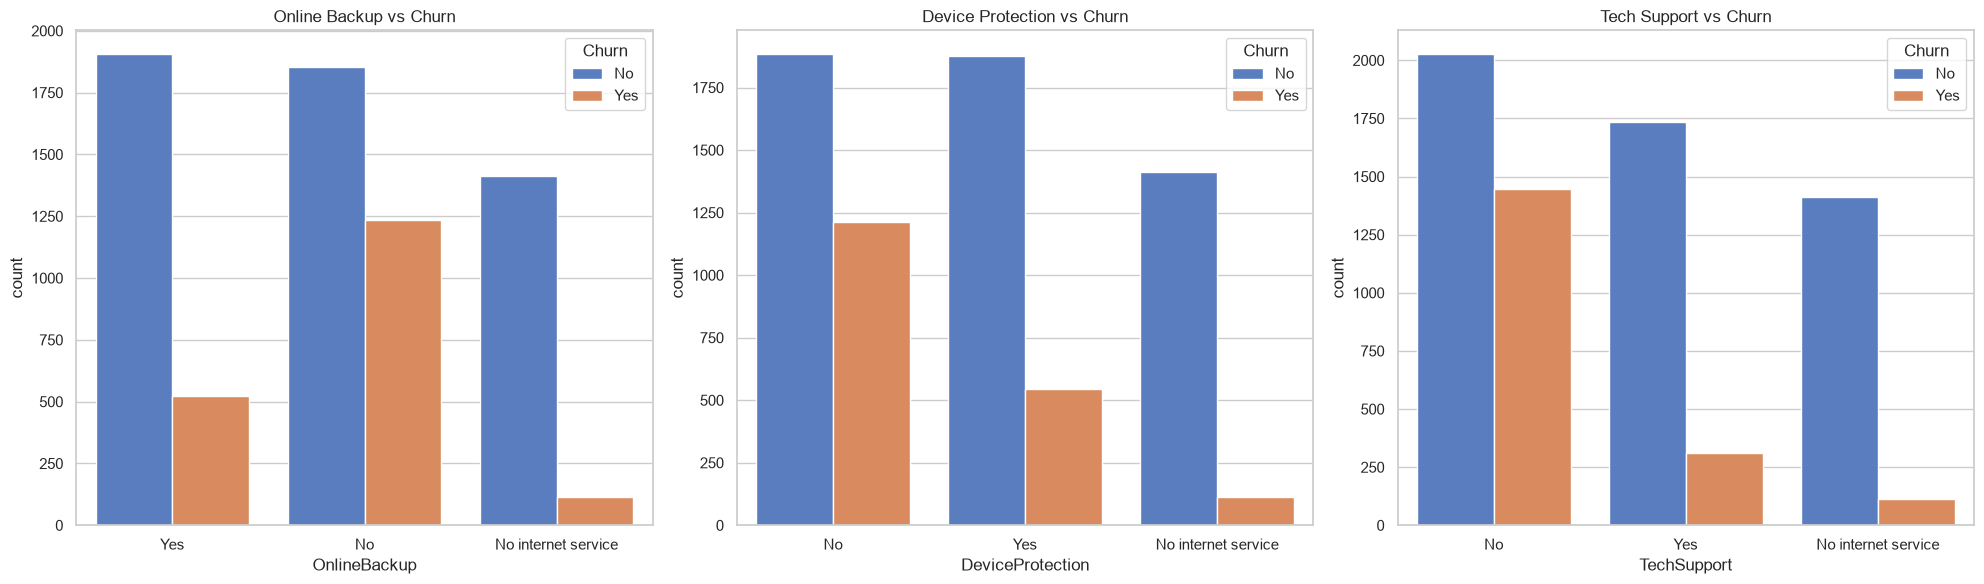

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.countplot(x='OnlineBackup', hue='Churn', data=df, ax=axes[0])
axes[0].set_title('Online Backup vs Churn')

sns.countplot(x='DeviceProtection', hue='Churn', data=df, ax=axes[1])
axes[1].set_title('Device Protection vs Churn')

sns.countplot(x='TechSupport', hue='Churn', data=df, ax=axes[2])
axes[2].set_title('Tech Support vs Churn')

plt.tight_layout()
plt.show()

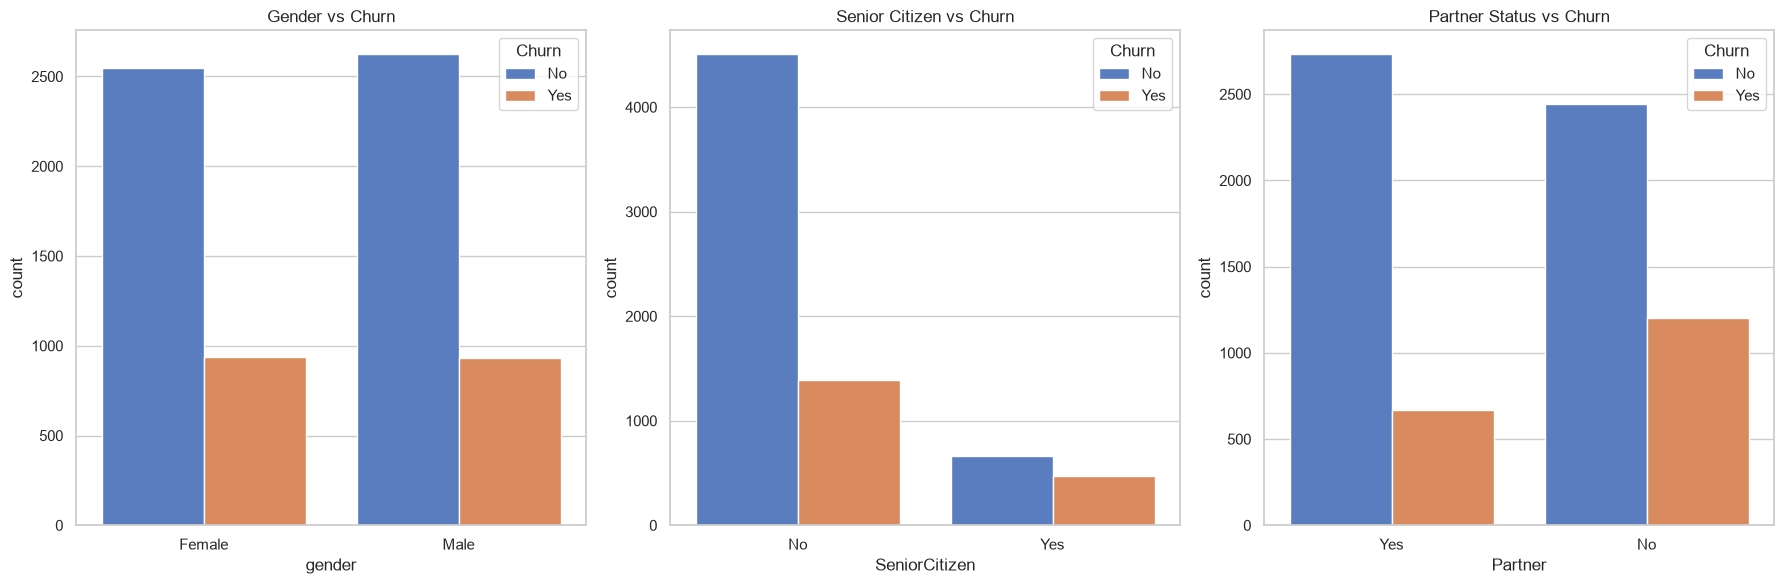

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

sns.countplot(x='gender', hue='Churn', data=df, ax=axes[0])
axes[0].set_title('Gender vs Churn')

sns.countplot(x='SeniorCitizen', hue='Churn', data=df, ax=axes[1])
axes[1].set_title('Senior Citizen vs Churn')
axes[1].set_xticks([0, 1], ['No', 'Yes'])

sns.countplot(x='Partner', hue='Churn', data=df, ax=axes[2])
axes[2].set_title('Partner Status vs Churn')

plt.tight_layout()
plt.show()

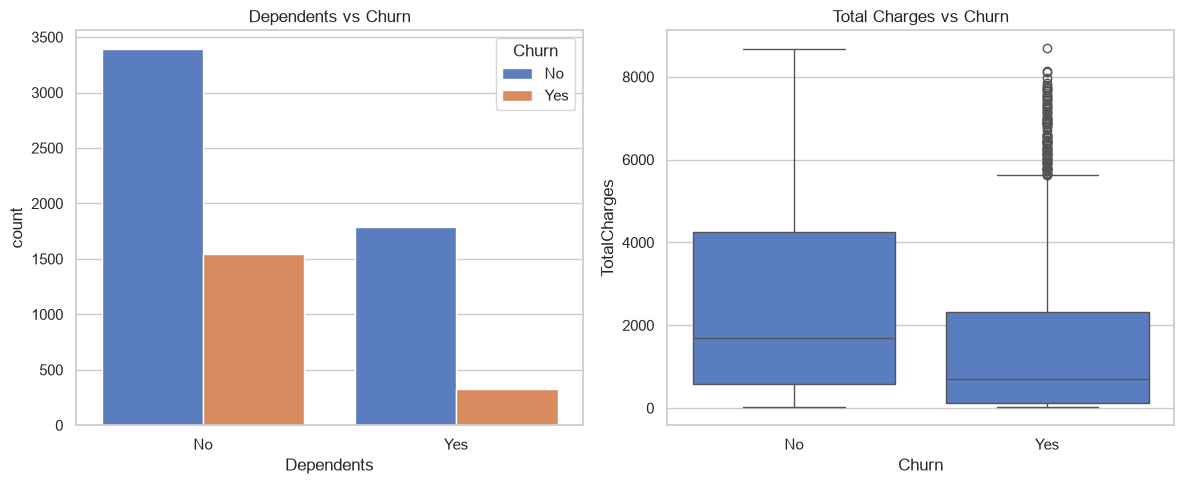

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x='Dependents', hue='Churn', data=df, ax=axes[0])
axes[0].set_title('Dependents vs Churn')

sns.boxplot(x='Churn', y='TotalCharges', data=df, ax=axes[1])
axes[1].set_title('Total Charges vs Churn')

plt.tight_layout()
plt.show()

In [44]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [46]:
df['TotalCharges'].isnull().sum()

np.int64(11)

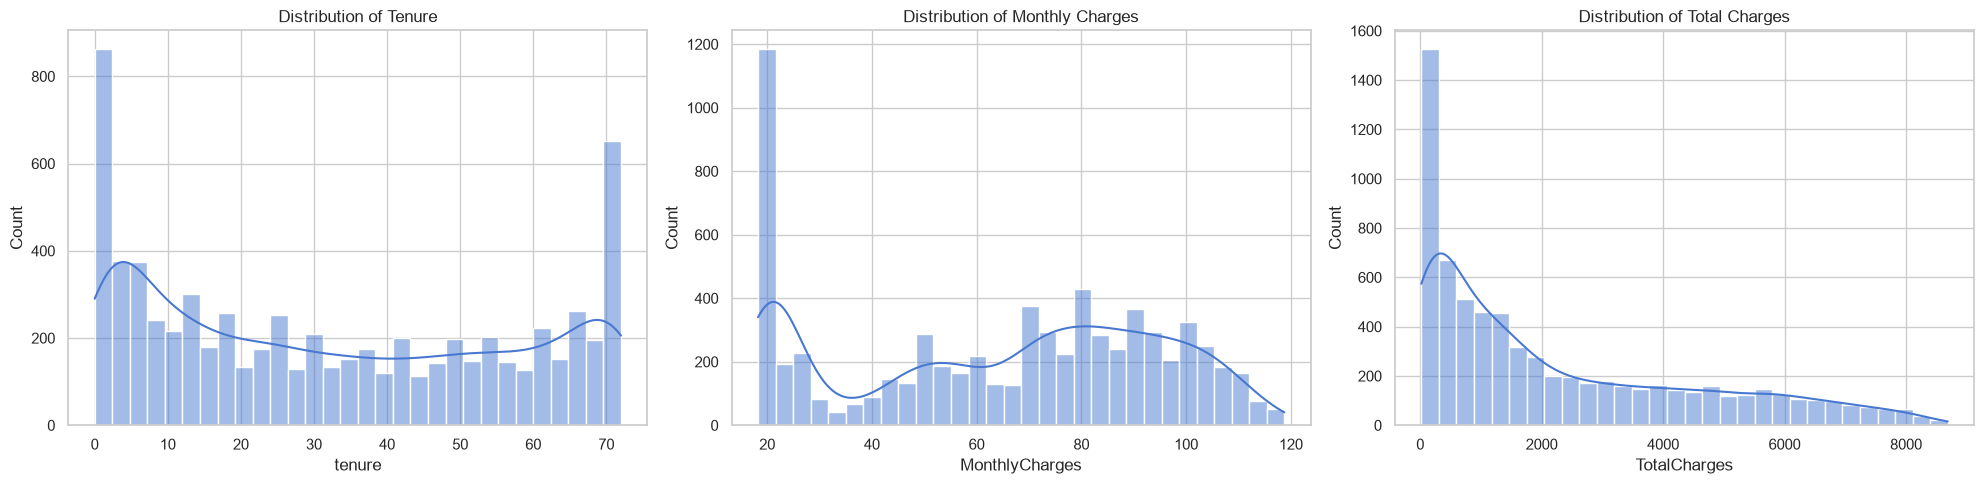

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sns.histplot(df['tenure'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Tenure')

sns.histplot(df['MonthlyCharges'], bins=30, kde=True, ax=axes[1])
axes[1].set_title('Distribution of Monthly Charges')

sns.histplot(df['TotalCharges'].dropna(), bins=30, kde=True, ax=axes[2])
axes[2].set_title('Distribution of Total Charges')

plt.tight_layout()
plt.show()

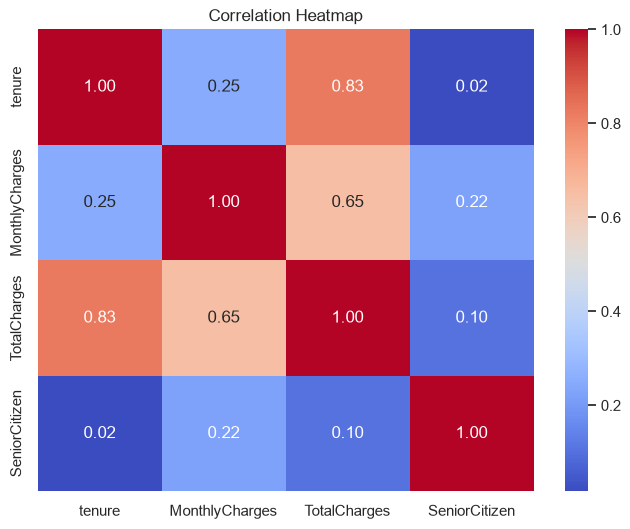

In [58]:
corr = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [64]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [65]:
df.dropna(subset=['TotalCharges'], inplace=True)

In [66]:
df.isnull().sum().sum()
df.shape

(7032, 21)

In [68]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

## Data Preprocessing

In [69]:
df.drop('customerID', axis=1, inplace=True)

In [79]:
X = df.drop('Churn', axis=1)
y = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [80]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

## Models Implemented

In [87]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier(),
    "SVC": SVC(random_state=42)
}
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

trained_pipelines = {}

for name, model in models.items():
    
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('clf', model)
    ])
    
    pipe.fit(X_train, y_train)
    
    trained_pipelines[name] = pipe
    print(f"Successfully trained: {name}")

Successfully trained: Logistic Regression
Successfully trained: Decision Tree
Successfully trained: Random Forest
Successfully trained: KNN
Successfully trained: SVC


## Evaluation

In [89]:
evaluation_results = []

for name, pipe in trained_pipelines.items():
    y_pred = pipe.predict(X_test)
    
    # Check if the model supports predict_proba (SVC might throw an error if not enabled)
    if hasattr(pipe, "predict_proba"):
        y_proba = pipe.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_proba)
    else:
        # Fallback for models without probability
        roc_auc = "N/A (No Proba)"
    
    report = classification_report(y_test, y_pred, output_dict=True)
    
    evaluation_results.append({
        "Model": name,
        "ROC-AUC": roc_auc,
        "Precision (Churn)": report['1']['precision'],
        "Recall (Churn)": report['1']['recall'],
        "F1-Score (Churn)": report['1']['f1-score']
    })

results_df = pd.DataFrame(evaluation_results)
print(results_df)

                 Model         ROC-AUC  Precision (Churn)  Recall (Churn)  \
0  Logistic Regression          0.8347           0.639394        0.564171   
1        Decision Tree        0.661071           0.502688        0.500000   
2        Random Forest         0.81015           0.600694        0.462567   
3                  KNN        0.774371           0.534351        0.561497   
4                  SVC  N/A (No Proba)           0.626712        0.489305   

   F1-Score (Churn)  
0          0.599432  
1          0.501340  
2          0.522659  
3          0.547588  
4          0.549550  


## Hyperparameter Tuning

In [91]:
param_grid = {
    'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'clf__solver': ['liblinear', 'lbfgs']
}

lr_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('clf', LogisticRegression(random_state=42))
])

grid_search = GridSearchCV(
    estimator=lr_pipe,
    param_grid=param_grid,
    cv=5,       
    scoring='roc_auc', 
    n_jobs=-1      
)

grid_search.fit(X_train, y_train)

print(f"Best Hyperparameters: {grid_search.best_params_}")
print(f"Best Cross-Validation ROC-AUC: {grid_search.best_score_:.4f}")

best_model = grid_search.best_estimator_

Best Hyperparameters: {'clf__C': 10, 'clf__solver': 'liblinear'}
Best Cross-Validation ROC-AUC: 0.8461


In [94]:
joblib.dump(best_model, 'churn_pipeline.pkl')
print("Model saved as 'churn_pipeline.pkl'")

Model saved as 'churn_pipeline.pkl'
